In [1]:
# Libraries 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
# Loading datasets
electricity_capacity_df = pd.read_csv("data-files/electricity-capacity-dataset.csv")
electricity_generation_df = pd.read_csv("data-files/electricity-generation-dataset.csv")

electricity_guide_df = pd.read_csv("data-files/electricity-capacity-guide.csv")

## Target Output Schema

Both source datasets will be converted into the following structure:

| Field | Type | Meaning | Example |
|---|---|---|---|
| `measure_type` | text | Type of measurement | `capacity` or `generation` |
| `region` | text | Region code or national aggregate | `BC` or `Canada` |
| `source` | text | Electricity source | `Hydro` |
| `year` | integer | Reporting year | `2005` |
| `value` | numeric | Capacity or generation value | `72889.8310` |
| `unit` | text | Unit from the source dataset | `MW` or `GW.h` |
| `source_file` | text | Name of the input file | `electricity-capacity-dataset.csv` |

For capacity records, `measure_type` is `capacity` and the unit is `MW`. For generation records, `measure_type` is `generation` and the unit is `GW.h`. Values are not converted between units.




## Source-to-Target Mapping and Rules

| Source | Target | Rule |
|---|---|---|
| Input dataset | `measure_type` | Set to `capacity` or `generation` based on the input file. |
| `Region` | `region` | Preserve the source value. Accept Canada and region codes listed in the data guide; Reject any other region value |
| `Source` | `source` | Preserve the source value; Reject values not listed in the guide. |
| `Year` | `year` | Convert to an integer. Reject missing, nonnumeric, or out-of-range years (valid range: 2005–2016). |
| `Data` | `value` | Convert to numeric. Reject missing or nonnumeric values; preserve valid zero values. |
| `Unit` | `unit` | Preserve the source unit. Require `MW` for capacity and `GW.h` for generation. |
| Input filename | `source_file` | Store the input filename for traceability. |

Rows with missing required values or invalid values will be written to the rejected-records output with a reason.
    Entirely blank rows will be recorded as rejected with reason `entirely_blank_row`. 
   Rows with duplicate target keys will be rejected with the reason duplicate_target_key. The reconciliation report lists the duplicate keys and counts.

In [3]:
electricity_capacity_df.head(5)

,Region,Source,Year,Data,Unit
0,Canada,Hydro,2005.0,72889.8310,MW
1,Canada,Wind,2005.0,557.3700,MW
2,Canada,Biomass,2005.0,1804.0882,MW
3,Canada,Solar,2005.0,16.7500,MW
4,Canada,Nuclear,2005.0,12805.0000,MW


In [4]:
electricity_generation_df.head(5)

,Region,Source,Year,Data,Unit
0,Canada,Hydro,2005,358386.9629,GW.h
1,Canada,Wind,2005,1453.4070,GW.h
2,Canada,Biomass,2005,7687.9980,GW.h
3,Canada,Solar,2005,0.0000,GW.h
4,Canada,Nuclear,2005,86668.5770,GW.h


In [5]:
electricity_guide_df.head(5)

,Column,Data Value or Column Name Indication,Description of Data Value or Column Name
0,Region,BC,Province of British Columbia
1,Region,AB,Province of Alberta
2,Region,SK,Province of Saskatchewan
3,Region,MB,Province of Manitoba
4,Region,ON,Province of Ontario


## Source Data Profile

The generation dataset contains 1,344 records covering 2005–2016. The capacity dataset contains 2,688 rows, including 1,344 entirely blank rows. I excluded those blank rows when checking for duplicates.

Both datasets contain region, source, year, value, and unit fields. Generation values use GW.h; capacity values use MW.

The distinct nonblank values are:
- **Regions:** Canada, BC, AB, SK, MB, ON, QC, NB, NS, NL, PE, YT, NT, NU
- **Sources:** Hydro, Wind, Biomass, Solar, Nuclear, Coal, Natural Gas, Oil and Diesel
- **Units:** GW.h for generation; MW for capacity

The profiling checks found:
- **Missing values in nonblank records:** None in either dataset. The capacity dataset has 1,344 entirely blank rows, reported separately.
- **Exact duplicate rows:** 0 in each dataset after excluding blank capacity rows.
- **Repeated Region + Source + Year keys:** None found in either dataset.
- **Invalid year or data values:** 0 in both fields for both datasets.

These are profiling findings only. No records have been cleaned or removed at this stage.

In [6]:
electricity_capacity_df.describe()

,Year,Data
count,1344.000000,1344.000000
mean,2010.500000,2376.166731
std,3.453337,8476.157854
min,2005.000000,0.000000
25%,2007.750000,0.000000
50%,2010.500000,77.900000
75%,2013.250000,860.952500
max,2016.000000,80403.110000


In [7]:
electricity_generation_df.describe()

,Year,Data
count,1344.000000,1344.000000
mean,2010.500000,11073.591309
std,3.453337,41706.131339
min,2005.000000,0.000000
25%,2007.750000,0.000000
50%,2010.500000,106.450000
75%,2013.250000,2322.250000
max,2016.000000,387967.770000


In [8]:
electricity_guide_df.describe()

,Column,Data Value or Column Name Indication,Description of Data Value or Column Name
count,23,23,23
unique,4,23,23
top,Region,BC,Province of British Columbia
freq,13,1,1


In [9]:
electricity_capacity_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2688 entries, 0 to 2687
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Region  1344 non-null   str    
 1   Source  1344 non-null   str    
 2   Year    1344 non-null   float64
 3   Data    1344 non-null   float64
 4   Unit    1344 non-null   str    
dtypes: float64(2), str(3)
memory usage: 105.1 KB


In [10]:
electricity_generation_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1344 entries, 0 to 1343
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Region  1344 non-null   str    
 1   Source  1344 non-null   str    
 2   Year    1344 non-null   int64  
 3   Data    1344 non-null   float64
 4   Unit    1344 non-null   str    
dtypes: float64(1), int64(1), str(3)
memory usage: 52.6 KB


In [11]:
electricity_guide_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 3 columns):
 #   Column                                    Non-Null Count  Dtype
---  ------                                    --------------  -----
 0   Column                                    23 non-null     str  
 1   Data Value or Column Name Indication      23 non-null     str  
 2   Description of Data Value or Column Name  23 non-null     str  
dtypes: str(3)
memory usage: 684.0 bytes


In [12]:
electricity_capacity_df.isnull().any()

Region    True
Source    True
Year      True
Data      True
Unit      True
dtype: bool

In [13]:
electricity_capacity_df.isnull().sum()

Region    1344
Source    1344
Year      1344
Data      1344
Unit      1344
dtype: int64

In [14]:
electricity_capacity_df.isna().all(axis=1).sum()

np.int64(1344)

In [15]:
electricity_generation_df.isnull().any()

Region    False
Source    False
Year      False
Data      False
Unit      False
dtype: bool

In [16]:
electricity_generation_df.isna().sum()


Region    0
Source    0
Year      0
Data      0
Unit      0
dtype: int64

In [17]:
electricity_guide_df.isnull().any()

Column                                      False
Data Value or Column Name Indication        False
Description of Data Value or Column Name    False
dtype: bool

In [18]:
electricity_capacity_df.duplicated().sum()

np.int64(1343)

In [19]:
electricity_generation_df.duplicated().sum()

np.int64(0)

In [20]:
electricity_generation_df[["Region", "Source", "Unit"]].nunique()

Region    14
Source     8
Unit       1
dtype: int64

In [21]:
electricity_generation_df["Region"].unique()


<StringArray>
['Canada',     'BC',     'AB',     'SK',     'MB',     'ON',     'QC',
     'NB',     'NS',     'NL',     'PE',     'YT',     'NT',     'NU']
Length: 14, dtype: str

In [22]:
electricity_generation_df["Source"].unique()

<StringArray>
[         'Hydro',           'Wind',        'Biomass',          'Solar',
        'Nuclear',           'Coal',    'Natural Gas', 'Oil and Diesel']
Length: 8, dtype: str

In [23]:
electricity_generation_df["Unit"].unique()

<StringArray>
['GW.h']
Length: 1, dtype: str

In [24]:
electricity_capacity_df[["Region", "Source", "Unit"]].nunique()

Region    14
Source     8
Unit       1
dtype: int64

In [25]:
electricity_capacity_df["Unit"].unique()

<StringArray>
['MW', nan]
Length: 2, dtype: str

In [26]:
electricity_capacity_df["Source"].unique()

<StringArray>
[         'Hydro',           'Wind',        'Biomass',          'Solar',
        'Nuclear',           'Coal',    'Natural Gas', 'Oil and Diesel',
              nan]
Length: 9, dtype: str

In [27]:
electricity_capacity_df["Region"].unique()

<StringArray>
['Canada',     'BC',     'AB',     'SK',     'MB',     'ON',     'QC',
     'NB',     'NS',     'NL',     'PE',     'YT',     'NT',     'NU',
      nan]
Length: 15, dtype: str

In [28]:
generation_nonblank = electricity_generation_df.dropna(how="all")

# Exact duplicate rows (all columns match)
generation_nonblank.duplicated().sum()

np.int64(0)

In [29]:
capacity_nonblank = electricity_capacity_df.dropna(how="all")

# Exact duplicate rows (all columns match)
capacity_nonblank.duplicated().sum()



np.int64(0)

In [30]:
# Rows involved in a repeated Region + Source + Year key
capacity_nonblank.dropna(
    subset=["Region", "Source", "Year"]
).duplicated(
    subset=["Region", "Source", "Year"],
    keep=False
).sum()

np.int64(0)

In [31]:
electricity_generation_df.duplicated().sum()

np.int64(0)

In [32]:
electricity_generation_df.dropna(
    subset=["Region", "Source", "Year"]
).duplicated(
    subset=["Region", "Source", "Year"],
    keep=False
).sum()

np.int64(0)

In [33]:
capacity_invalid_years = (
    pd.to_numeric(electricity_capacity_df["Year"], errors="coerce").isna()
    & electricity_capacity_df["Year"].notna()
).sum()
capacity_invalid_data = (
    pd.to_numeric(electricity_capacity_df["Data"], errors="coerce").isna()
    & electricity_capacity_df["Data"].notna()
).sum()

capacity_invalid_years, capacity_invalid_data


(np.int64(0), np.int64(0))

In [34]:
generation_invalid_years = (
    pd.to_numeric(electricity_generation_df["Year"], errors="coerce").isna()
    & electricity_generation_df["Year"].notna()
).sum()

generation_invalid_data = (
    pd.to_numeric(electricity_generation_df["Data"], errors="coerce").isna()
    & electricity_generation_df["Data"].notna()
).sum()

generation_invalid_years, generation_invalid_data

(np.int64(0), np.int64(0))

In [35]:
# Merge data
electricity_merged_df = pd.merge(
    electricity_capacity_df, 
    electricity_generation_df, 
    on=['Region', 'Source', 'Year'], 
    suffixes=('_capacity', '_generation')
)

In [36]:
electricity_provinces_df = electricity_merged_df[electricity_merged_df['Region'] != 'Canada']

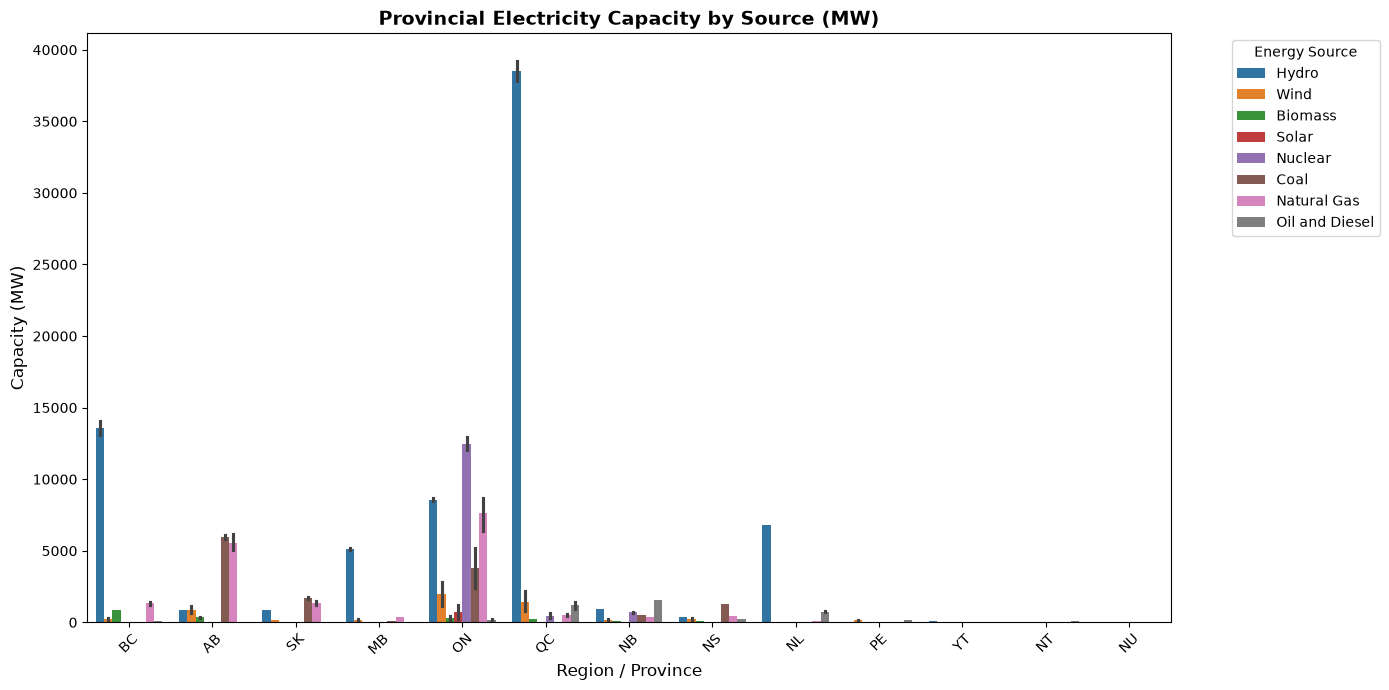

In [43]:
plt.figure(figsize=(14, 7))
sns.barplot(data=electricity_provinces_df, x='Region', y='Data_capacity', hue='Source', palette='tab10')
plt.title('Provincial Electricity Capacity by Source (MW)', fontsize=14, fontweight='bold')
plt.xlabel('Region / Province', fontsize=12)
plt.ylabel('Capacity (MW)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Energy Source', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('provincial_capacity_comparison.png')
plt.show()
plt.close()

In [44]:
#Canadian generation by year and source: Returns the recorded generation value for each source and year, filtered to Canada’s national aggregate. Values are in GW.h.

with sqlite3.connect("output/electricity_metrics.db") as conn:
    generation_by_year = pd.read_sql_query(
        """
        SELECT year, source, SUM(value) AS total_generation_gw
        FROM electricity_metrics
        WHERE measure_type = 'generation' AND region = 'Canada'
        GROUP BY year, source
        ORDER BY year, source
        """,
        conn,
    )

generation_by_year.head(8)

,year,source,total_generation_gw
0,2005,Biomass,7687.9980
1,2005,Coal,96750.2000
2,2005,Hydro,358386.9629
3,2005,Natural Gas,40874.5375
4,2005,Nuclear,86668.5770
5,2005,Oil and Diesel,10608.1483
6,2005,Solar,0.0000
7,2005,Wind,1453.4070


In [45]:
#2016 capacity by region and source: Shows reported capacity for each region and energy source, in MW. The Canada row is the national aggregate and is shown alongside regional records.
capacity_by_region_and_source_for_a_selected = pd.read_sql_query(
    """
    SELECT region, source, SUM(value) AS total_capacity_mw
    FROM electricity_metrics
    WHERE measure_type = 'capacity'
    AND year = 2016
    GROUP BY region, source
    ORDER BY total_capacity_mw DESC;
    """,
    conn    
)
capacity_by_region_and_source_for_a_selected.head()

,region,source,total_capacity_mw
0,Canada,Hydro,80403.11
1,QC,Hydro,40396.95
2,Canada,Natural Gas,21499.42
3,BC,Hydro,15708.87
4,Canada,Nuclear,14273.00


In [46]:
#average Canadian generation by source: Calculates each source’s average annual generation across the 12 years in the dataset.
summary_by_source_across_all_years = pd.read_sql_query(
    """
   SELECT source, COUNT(*) AS year_count, AVG(value) AS avg_generation_gwh
   FROM electricity_metrics
   WHERE measure_type = 'generation'
   AND region = 'Canada'
   GROUP BY source
   ORDER BY avg_generation_gwh DESC;
    """,
    conn
)

summary_by_source_across_all_years.head()

,source,year_count,avg_generation_gwh
0,Hydro,12,369351.120708
1,Nuclear,12,91345.901167
2,Coal,12,76241.578533
3,Natural Gas,12,55020.693125
4,Wind,12,12645.399450


In [47]:
#An empty result indicates there are no duplicate keys in the accepted records.”
duplicate_keys = pd.read_sql_query(
        """
        SELECT
            measure_type,
            region,
            source,
            year,
            COUNT(*) AS row_count
        FROM electricity_metrics
        GROUP BY measure_type, region, source, year
        HAVING COUNT(*) > 1
        ORDER BY row_count DESC
        """,
        conn,
    )

duplicate_keys.head()

,measure_type,region,source,year,row_count
